# Мультишаговая генерация: 5 шагов подряд

Цель: проверить устойчивость политик (π_ref, R0, R3) при генерации 
не одного айтема, а последовательности из 5. Измерить:
- как меняется RM score (растет ли → reward hacking на сгенерированном контексте),
- попадание в реальное будущее пользователя (hit@1) — должно падать,
- сдвиг в популярное (item_mean, popularity),
- энтропию и KL к π_ref (не сколлапсировала ли политика).

### Импорты и пути

In [1]:
import sys
sys.path.append('../src')

import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import importlib
from collections import Counter
import pickle

from tqdm.auto import tqdm

import reward_functions as rf_mod
importlib.reload(rf_mod)
from reward_functions import RMReward, build_item_mean_map

from dataset import build_item_vocab
from model import create_model
from reward_model import create_reward_model
from rm_index import RMIndex
from metrics import build_eval_targets, build_context

PROC = Path('../data/processed')
RESULTS = Path('../results')
RESULTS_MS = RESULTS / 'multistep_results'
RESULTS_MS.mkdir(exist_ok=True)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")

Device: cuda


### Данные и словарь

In [2]:
train_df = pd.read_parquet(PROC / 'train.parquet')
val_df   = pd.read_parquet(PROC / 'val.parquet')
test_df  = pd.read_parquet(PROC / 'test.parquet')

item2idx, idx2item = build_item_vocab(train_df)
vocab_size = len(item2idx) + 2
print(f"Vocab size: {vocab_size}")

Vocab size: 14937


### Загрузка моделей

In [3]:
def load_gpt2_policy(ckpt):
    m = create_model(vocab_size=vocab_size)
    m.load_state_dict(torch.load(ckpt, map_location='cpu'))
    return m

# π_ref
ref_policy = load_gpt2_policy(RESULTS / 'checkpoints_v2' / 'best_model.pt').to(device).eval()
for p in ref_policy.parameters():
    p.requires_grad = False

# R0
policy_r0 = load_gpt2_policy(
    RESULTS / 'checkpoints_rl_r0_beta2.0' / 'final_model.pt'
).to(device).eval()
for p in policy_r0.parameters():
    p.requires_grad = False

# R3 (победитель: λ=0.03, β=2.0)
policy_r3 = load_gpt2_policy(
    RESULTS / 'checkpoints_rl_r3_lam0.03_beta2.0' / 'final_model.pt'
).to(device).eval()
for p in policy_r3.parameters():
    p.requires_grad = False

# RM
rm = create_reward_model(vocab_size=vocab_size,
                         init_from=RESULTS / 'checkpoints_v2' / 'best_model.pt')
rm.load_state_dict(torch.load(RESULTS / 'checkpoints_rm_v2' / 'best_model.pt',
                              map_location='cpu'))
rm = rm.to(device).eval()
for p in rm.parameters():
    p.requires_grad = False

print(f"Loaded: π_ref, R0, R3, RM")

[transformers] Model config: bos_token_id must be `None` or an integer within the vocabulary (between 0 and 14936), got 50256. This may result in unexpected behavior.
[transformers] Model config: eos_token_id must be `None` or an integer within the vocabulary (between 0 and 14936), got 50256. This may result in unexpected behavior.


[create_reward_model] Backbone: загружено 28 тензоров
[create_reward_model] candidate_emb инициализирован из wte
Loaded: π_ref, R0, R3, RM


### RMIndex и item_mean_map

In [4]:
all_df = pd.concat([train_df, val_df, test_df], ignore_index=True)
idx = RMIndex(all_df, item2idx, t1='2021-07-24', t2='2021-08-04')

item_mean_map = build_item_mean_map(idx, idx2item)

# Популярность для диагностики
popularity_count = train_df.groupby('item_id').size().to_dict()
print(f"item_mean_map: {len(item_mean_map)} айтемов, "
      f"popularity: {len(popularity_count)} айтемов")

RMIndex: 4,632,197 событий
  train: 2,789,962
  val:   371,021
  test:  474,130
item_mean_map: 14434 айтемов, popularity: 14935 айтемов


### Helper-функции

In [5]:
@torch.no_grad()
def _batched_policy_logits(policy, contexts, item2idx, max_len=50, device='cuda',
                            batch_b=512, apply_masking=True, desc=None):
    B = len(contexts)
    out = []
    n_batches = (B + batch_b - 1) // batch_b
    pbar = tqdm(range(0, B, batch_b),
                desc=desc or "policy logits",
                total=n_batches, leave=False)
    for s in pbar:
        end = min(s + batch_b, B)
        inp = torch.zeros(end - s, max_len, dtype=torch.long, device=device)
        for i, ctx in enumerate(contexts[s:end]):
            recent = ctx[-max_len:]
            indexed = [item2idx.get(int(x), 1) for x in recent]
            if indexed:
                inp[i, -len(indexed):] = torch.tensor(indexed, device=device)
        logits = policy(inp).logits[:, -1, :].clone()
        if apply_masking:
            logits[:, 0] = -1e9
            logits[:, 1] = -1e9
            for i, ctx in enumerate(contexts[s:end]):
                s_items = [item2idx[int(x)] for x in ctx if int(x) in item2idx]
                if s_items:
                    logits[i, torch.tensor(s_items, device=device)] = -1e9
        out.append(logits)
    return torch.cat(out, dim=0)


@torch.no_grad()
def score_candidates(rm, contexts, cand_idx, item2idx,
                     max_len=50, chunk=8192, batch_b=256, device='cuda', desc=None):
    B = len(contexts)
    L = max_len
    M = cand_idx.shape[1]
    hist = torch.zeros(B, L - 1, dtype=torch.long, device=device)
    for i, ctx in enumerate(contexts):
        recent = ctx[-(L - 1):] if ctx else []
        indexed = [item2idx.get(int(x), 1) for x in recent]
        if indexed:
            hist[i, -len(indexed):] = torch.tensor(indexed, device=device)
    out = []
    n_batches = (B + batch_b - 1) // batch_b
    pbar = tqdm(range(0, B, batch_b),
                desc=desc or f"RM score {B}x{M}",
                total=n_batches, leave=False)
    for s in pbar:
        end = min(s + batch_b, B)
        h = hist[s:end].unsqueeze(1).expand(-1, M, -1)
        c = cand_idx[s:end].unsqueeze(2)
        seq = torch.cat([h, c], dim=2).reshape(-1, L)
        for s2 in range(0, seq.size(0), chunk):
            out.append(torch.sigmoid(rm(seq[s2:s2 + chunk])))
    return torch.cat(out).view(B, M)

### Подготовка eval_users и real_future

In [6]:
test_targets = build_eval_targets(test_df)
test_context = build_context(train_df, val_df)

test_users = test_targets['user_id'].unique()
np.random.seed(123)
eval_users = np.random.choice(test_users, size=2000, replace=False).tolist()

# Контексты (train+val history)
eval_contexts = []
for u in eval_users:
    ctx = test_context.get(u)
    items = ctx['items'] if ctx else []
    eval_contexts.append(list(items)[-50:])

# Real future: все айтемы пользователя в test, по дате
test_sorted = test_df.sort_values(['user_id', 'last_watch_dt'])
real_future = {}
for u in eval_users:
    items = test_sorted[test_sorted['user_id'] == u]['item_id'].tolist()
    real_future[u] = items

# Проверка
n_with_future = sum(1 for v in real_future.values() if len(v) > 0)
n_with_5plus = sum(1 for v in real_future.values() if len(v) >= 5)
print(f"Eval users: {len(eval_users)}")
print(f"  с реальным будущим: {n_with_future}")
print(f"  с 5+ будущими айтемами: {n_with_5plus}")
print(f"  пример (user {eval_users[0]}): контекст {len(eval_contexts[0])} айтемов, "
      f"будущее {len(real_future[eval_users[0]])} айтемов")

Eval users: 2000
  с реальным будущим: 2000
  с 5+ будущими айтемами: 457
  пример (user 453734): контекст 2 айтемов, будущее 2 айтемов


### Функция multistep_generate

Генерирует `n_steps` айтемов подряд, добавляя каждый в контекст. 
На каждом шаге записывает метрики: RM score, hit в real_future, 
популярность, item_mean, энтропию, log π_ref (для KL).

In [7]:
@torch.no_grad()
def multistep_generate(policy, ref_policy_for_kl, initial_contexts, item2idx, idx2item,
                       rm, item_mean_map, popularity_count,
                       real_future_list, max_len=50, n_steps=5,
                       device='cuda', apply_masking=True, desc=None):
    """
    initial_contexts: list[list[item_id]]
    real_future_list: list[list[item_id]] — реальное будущее для каждого пользователя
    Возвращает: dict со метриками по шагам и сгенерированными айтемами.
    """
    B = len(initial_contexts)
    contexts = [list(c) for c in initial_contexts]

    generated = [[] for _ in range(B)]
    metrics = {
        'rm_score': [[] for _ in range(n_steps)],
        'hit': [[] for _ in range(n_steps)],
        'popularity': [[] for _ in range(n_steps)],
        'item_mean': [[] for _ in range(n_steps)],
        'entropy': [[] for _ in range(n_steps)],
        'logp_ref': [[] for _ in range(n_steps)],
        'repeat': [[] for _ in range(n_steps)],
    }

    for step in range(n_steps):
        # 1. Logits текущей политики (с маскировкой seen)
        logits = _batched_policy_logits(policy, contexts, item2idx, max_len, device,
                                         apply_masking=apply_masking,
                                         desc=desc or f"step {step+1} policy")
        # 2. Top-1
        probs = torch.softmax(logits, dim=-1)
        top_idx = torch.multinomial(probs, num_samples=1).squeeze(-1)
        
        # 3. Энтропия (по softmax всех логитов, кроме -1e9)
        probs = torch.softmax(logits, dim=-1)
        log_probs = torch.log_softmax(logits, dim=-1)
        entropy = -(probs * log_probs).sum(-1).cpu()  # (B,)
        
        # 4. log π_ref на текущих контекстах (для KL)
        if ref_policy_for_kl is not None:
            ref_logits = _batched_policy_logits(ref_policy_for_kl, contexts, item2idx,
                                                 max_len, device, apply_masking=apply_masking,
                                                 desc=desc or f"step {step+1} ref")
            ref_log_probs = torch.log_softmax(ref_logits, dim=-1)
            logp_ref_selected = ref_log_probs.gather(1, top_idx.unsqueeze(1)).squeeze(1).cpu()
        else:
            logp_ref_selected = torch.zeros(B)
        
        # 5. RM score для выбранных действий (на контексте ДО добавления)
        top_list = [[idx2item[int(i)] for i in top_idx.cpu()]]
        rm_scores = score_candidates(rm, contexts, top_idx.unsqueeze(1), item2idx,
                                      max_len=max_len, device=device,
                                      desc=desc or f"step {step+1} RM")
        rm_scores = rm_scores.squeeze(1).cpu()  # (B,)
        
        # 6. Метрики
        for i, act_idx in enumerate(top_idx.cpu().tolist()):
            item = idx2item[int(act_idx)]
            generated[i].append(item)
            contexts[i].append(item)
            
            metrics['rm_score'][step].append(float(rm_scores[i]))
            metrics['hit'][step].append(1.0 if item in real_future_list[i] else 0.0)
            metrics['popularity'][step].append(popularity_count.get(item, 0))
            metrics['item_mean'][step].append(item_mean_map.get(item, 0.5))
            metrics['entropy'][step].append(float(entropy[i]))
            metrics['logp_ref'][step].append(float(logp_ref_selected[i]))
            # repeat: айтем уже был в исходном контексте (после маскирования = 0, кроме edge case)
            metrics['repeat'][step].append(
                1.0 if item in initial_contexts[i] else 0.0
            )
    
    # Агрегация
    result = {
        'generated': generated,
        'contexts_final': contexts,
    }
    for k, v in metrics.items():
        result[k] = [float(np.mean(step_vals)) if step_vals else 0.0
                     for step_vals in v]
    return result

### Функция для "real" reference

In [8]:
@torch.no_grad()
def multistep_real(initial_contexts, real_future_list, rm, item2idx, idx2item,
                    max_len=50, n_steps=5, device='cuda'):
    """
    Генерирует "реальную" последовательность: добавляет к контексту 
    реальные айтемы из real_future по порядку. Считает RM score.
    Если у пользователя меньше n_steps будущих айтемов — RM score = nan 
    для этих шагов, усредняем по не-nan.
    """
    B = len(initial_contexts)
    contexts = [list(c) for c in initial_contexts]
    rm_scores_by_step = [[] for _ in range(n_steps)]
    
    for step in range(n_steps):
        # Какие пользователи имеют этот шаг?
        valid_idx = [i for i in range(B) if step < len(real_future_list[i])]
        if not valid_idx:
            continue
        step_contexts = [contexts[i] for i in valid_idx]
        step_acts = [real_future_list[i][step] for i in valid_idx]
        step_act_idx = torch.tensor([item2idx.get(int(a), 1) for a in step_acts],
                                     device=device).unsqueeze(1)
        
        scores = score_candidates(rm, step_contexts, step_act_idx, item2idx,
                                   max_len=max_len, device=device,
                                   desc=f"real step {step+1}")
        scores = scores.squeeze(1).cpu().tolist()
        
        for i_local, i_orig in enumerate(valid_idx):
            rm_scores_by_step[step].append(scores[i_local])
            contexts[i_orig].append(step_acts[i_local])
    
    return {
        'rm_score': [float(np.mean(v)) if v else float('nan') for v in rm_scores_by_step],
        'n_valid': [len(v) for v in rm_scores_by_step],
    }

### Запуск мультишага для 4 сценариев

- **π_ref**: контроль.
- **R0 (β=2.0)**: без ограничений.
- **R3 (λ=0.03, β=2.0)**: с ограничением через log π_ref.
- **Real**: реальное будущее (reference для RM score).

In [9]:
n_steps = 5

print(f"\n{'='*70}\nπ_ref (base)\n{'='*70}")
ms_ref = multistep_generate(
    policy=ref_policy, ref_policy_for_kl=None,
    initial_contexts=eval_contexts, item2idx=item2idx, idx2item=idx2item,
    rm=rm, item_mean_map=item_mean_map, popularity_count=popularity_count,
    real_future_list=[real_future[u] for u in eval_users],
    n_steps=n_steps, device=device, desc="π_ref multistep",
)

print(f"\n{'='*70}\nR0 (β=2.0)\n{'='*70}")
ms_r0 = multistep_generate(
    policy=policy_r0, ref_policy_for_kl=ref_policy,
    initial_contexts=eval_contexts, item2idx=item2idx, idx2item=idx2item,
    rm=rm, item_mean_map=item_mean_map, popularity_count=popularity_count,
    real_future_list=[real_future[u] for u in eval_users],
    n_steps=n_steps, device=device, desc="R0 multistep",
)

print(f"\n{'='*70}\nR3 (λ=0.03, β=2.0)\n{'='*70}")
ms_r3 = multistep_generate(
    policy=policy_r3, ref_policy_for_kl=ref_policy,
    initial_contexts=eval_contexts, item2idx=item2idx, idx2item=idx2item,
    rm=rm, item_mean_map=item_mean_map, popularity_count=popularity_count,
    real_future_list=[real_future[u] for u in eval_users],
    n_steps=n_steps, device=device, desc="R3 multistep",
)

print(f"\n{'='*70}\nReal reference (RM score на реальном будущем)\n{'='*70}")
ms_real = multistep_real(
    initial_contexts=eval_contexts,
    real_future_list=[real_future[u] for u in eval_users],
    rm=rm, item2idx=item2idx, idx2item=idx2item,
    n_steps=n_steps, device=device,
)

print("\nВсе мультишаги завершены")


π_ref (base)


π_ref multistep:   0%|          | 0/4 [00:00<?, ?it/s]

π_ref multistep:   0%|          | 0/8 [00:00<?, ?it/s]

π_ref multistep:   0%|          | 0/4 [00:00<?, ?it/s]

π_ref multistep:   0%|          | 0/8 [00:00<?, ?it/s]

...

real step 2:   0%|          | 0/5 [00:00<?, ?it/s]

real step 3:   0%|          | 0/4 [00:00<?, ?it/s]

real step 4:   0%|          | 0/3 [00:00<?, ?it/s]

real step 5:   0%|          | 0/2 [00:00<?, ?it/s]


Все мультишаги завершены


### Сводная таблица по шагам

In [10]:
def print_multistep_table(name, ms):
    print(f"\n{'='*90}")
    print(f"{name}")
    print(f"{'='*90}")
    print(f"{'Шаг':>4}  {'RM score':>10}  {'Hit@1':>8}  {'Popularity':>12}  "
          f"{'item_mean':>10}  {'Entropy':>10}  {'Repeat':>8}")
    print("-" * 90)
    for step in range(n_steps):
        print(f"{step+1:>4}  {ms['rm_score'][step]:>10.4f}  {ms['hit'][step]:>8.4f}  "
              f"{ms['popularity'][step]:>12.1f}  {ms['item_mean'][step]:>10.4f}  "
              f"{ms['entropy'][step]:>10.4f}  {ms['repeat'][step]:>8.4f}")

print_multistep_table("π_ref (base)", ms_ref)
print_multistep_table("R0 (β=2.0)", ms_r0)
print_multistep_table("R3 (λ=0.03, β=2.0)", ms_r3)

print(f"\n{'='*90}")
print("Real reference (RM score на реальных айтемах)")
print(f"{'='*90}")
print(f"{'Шаг':>4}  {'RM score':>10}  {'n_valid':>10}")
print("-" * 90)
for step in range(n_steps):
    print(f"{step+1:>4}  {ms_real['rm_score'][step]:>10.4f}  {ms_real['n_valid'][step]:>10}")


π_ref (base)
 Шаг    RM score     Hit@1    Popularity   item_mean     Entropy    Repeat
------------------------------------------------------------------------------------------
   1      0.5018    0.0360       25744.8      0.5193      5.8749    0.0000
   2      0.5005    0.0285       22500.8      0.5162      5.9060    0.0000
   3      0.5012    0.0290       20059.8      0.5150      5.9622    0.0000
   4      0.5037    0.0225       17446.5      0.5171      6.0176    0.0000
   5      0.4941    0.0270       16244.9      0.5091      6.0754    0.0000

R0 (β=2.0)
 Шаг    RM score     Hit@1    Popularity   item_mean     Entropy    Repeat
------------------------------------------------------------------------------------------
   1      0.5455    0.0385       32325.7      0.5606      5.5562    0.0000
   2      0.5391    0.0385       26635.0      0.5525      5.5862    0.0000
   3      0.5377    0.0310       24941.5      0.5473      5.6805    0.0000
   4      0.5364    0.0270       20771.8  

### Визуализация: RM score по шагам

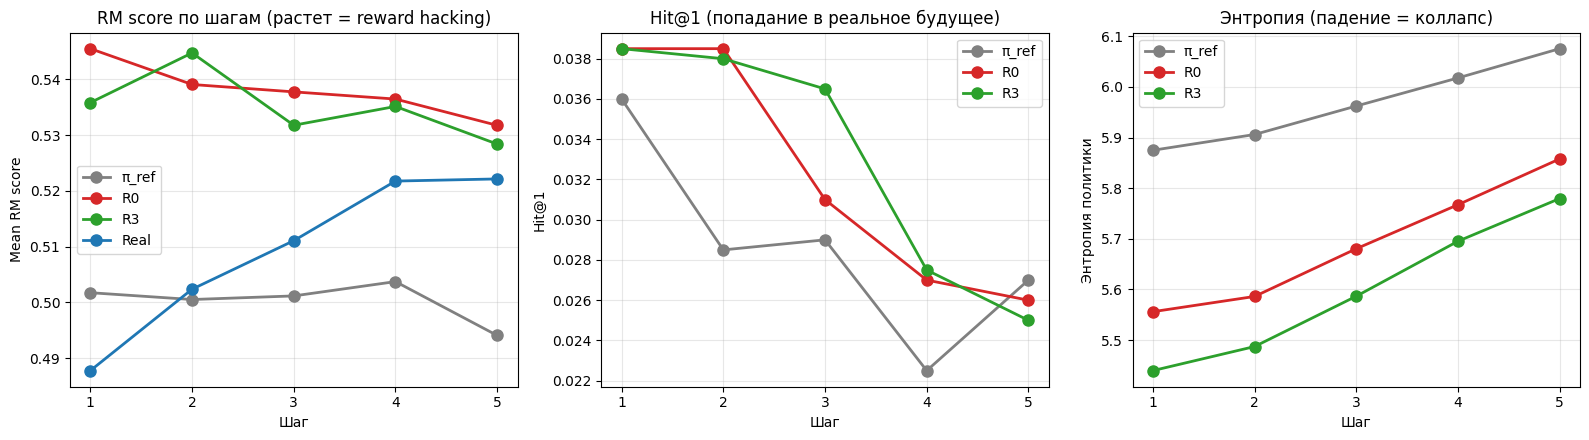

Сохранено: ..\results\multistep_results\multistep_metrics.png


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
steps = np.arange(1, n_steps + 1)

# RM score
ax = axes[0]
for name, ms, color in [('π_ref', ms_ref, 'gray'),
                         ('R0', ms_r0, '#d62728'),
                         ('R3', ms_r3, '#2ca02c'),
                         ('Real', ms_real, '#1f77b4')]:
    ax.plot(steps, ms['rm_score'], 'o-', label=name, color=color, linewidth=2, markersize=8)
ax.set_xlabel('Шаг')
ax.set_ylabel('Mean RM score')
ax.set_title('RM score по шагам (растет = reward hacking)')
ax.grid(alpha=0.3); ax.legend(); ax.set_xticks(steps)

# Hit@1
ax = axes[1]
for name, ms, color in [('π_ref', ms_ref, 'gray'),
                         ('R0', ms_r0, '#d62728'),
                         ('R3', ms_r3, '#2ca02c')]:
    ax.plot(steps, ms['hit'], 'o-', label=name, color=color, linewidth=2, markersize=8)
ax.set_xlabel('Шаг')
ax.set_ylabel('Hit@1')
ax.set_title('Hit@1 (попадание в реальное будущее)')
ax.grid(alpha=0.3); ax.legend(); ax.set_xticks(steps)

# Entropy
ax = axes[2]
for name, ms, color in [('π_ref', ms_ref, 'gray'),
                         ('R0', ms_r0, '#d62728'),
                         ('R3', ms_r3, '#2ca02c')]:
    ax.plot(steps, ms['entropy'], 'o-', label=name, color=color, linewidth=2, markersize=8)
ax.set_xlabel('Шаг')
ax.set_ylabel('Энтропия политики')
ax.set_title('Энтропия (падение = коллапс)')
ax.grid(alpha=0.3); ax.legend(); ax.set_xticks(steps)

plt.tight_layout()
out_path = RESULTS_MS / 'multistep_metrics.png'
plt.savefig(out_path, dpi=130, bbox_inches='tight')
plt.show()
print(f"Сохранено: {out_path}")

### Визуализация: популярность и item_mean

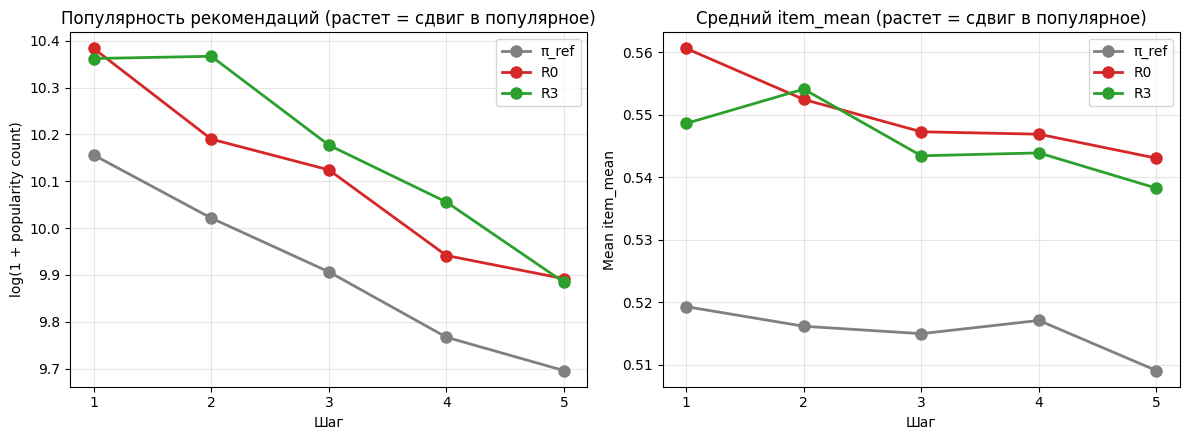

Сохранено: ..\results\multistep_results\multistep_popularity.png


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Popularity (log scale)
ax = axes[0]
for name, ms, color in [('π_ref', ms_ref, 'gray'),
                         ('R0', ms_r0, '#d62728'),
                         ('R3', ms_r3, '#2ca02c')]:
    ax.plot(steps, np.log1p(ms['popularity']), 'o-',
            label=name, color=color, linewidth=2, markersize=8)
ax.set_xlabel('Шаг')
ax.set_ylabel('log(1 + popularity count)')
ax.set_title('Популярность рекомендаций (растет = сдвиг в популярное)')
ax.grid(alpha=0.3); ax.legend(); ax.set_xticks(steps)

# item_mean
ax = axes[1]
for name, ms, color in [('π_ref', ms_ref, 'gray'),
                         ('R0', ms_r0, '#d62728'),
                         ('R3', ms_r3, '#2ca02c')]:
    ax.plot(steps, ms['item_mean'], 'o-',
            label=name, color=color, linewidth=2, markersize=8)
ax.set_xlabel('Шаг')
ax.set_ylabel('Mean item_mean')
ax.set_title('Средний item_mean (растет = сдвиг в популярное)')
ax.grid(alpha=0.3); ax.legend(); ax.set_xticks(steps)

plt.tight_layout()
out_path = RESULTS_MS / 'multistep_popularity.png'
plt.savefig(out_path, dpi=130, bbox_inches='tight')
plt.show()
print(f"Сохранено: {out_path}")

### Примеры рекомендаций (3 пользователя)

In [13]:
print(f"\n{'='*90}")
print("ПРИМЕРЫ 5-шаговых рекомендаций")
print(f"{'='*90}")

# 3 пользователя со средней длиной истории
sample_users = [u for u in eval_users
                if 5 <= len(test_context.get(u, {}).get('items', [])) <= 30][:3]

for u in sample_users:
    idx_u = eval_users.index(u)
    print(f"\n--- User {u} ---")
    hist = eval_contexts[idx_u]
    print(f"История (последние 5): {hist[-5:]}")
    print(f"Реальное будущее (первые 5): {real_future[u][:5]}")
    print(f"\n  π_ref:  {ms_ref['generated'][idx_u]}")
    print(f"  R0:     {ms_r0['generated'][idx_u]}")
    print(f"  R3:     {ms_r3['generated'][idx_u]}")


ПРИМЕРЫ 5-шаговых рекомендаций

--- User 475931 ---
История (последние 5): [6455, 7829, 798, 3509, 1617]
Реальное будущее (первые 5): [8350]

  π_ref:  [np.int64(7417), np.int64(13020), np.int64(12192), np.int64(10240), np.int64(8636)]
  R0:     [np.int64(9900), np.int64(4141), np.int64(11778), np.int64(4533), np.int64(13326)]
  R3:     [np.int64(12192), np.int64(9896), np.int64(1264), np.int64(13262), np.int64(5803)]

--- User 440945 ---
История (последние 5): [3638, 13865, 11338, 15701, 9808]
Реальное будущее (первые 5): [7424, 14915]

  π_ref:  [np.int64(8109), np.int64(7082), np.int64(12849), np.int64(8821), np.int64(12546)]
  R0:     [np.int64(14), np.int64(5794), np.int64(13788), np.int64(11228), np.int64(8139)]
  R3:     [np.int64(14804), np.int64(11454), np.int64(4151), np.int64(9728), np.int64(7160)]

--- User 927033 ---
История (последние 5): [6443, 12192, 14982, 13964, 13262]
Реальное будущее (первые 5): [11245]

  π_ref:  [np.int64(1381), np.int64(12544), np.int64(12080), 

### Сводная таблица

In [14]:
def summarize_ms(ms, name):
    return {
        'model': name,
        'rm_score_1': ms['rm_score'][0],
        'rm_score_5': ms['rm_score'][-1],
        'rm_growth': ms['rm_score'][-1] - ms['rm_score'][0],
        'hit_1': ms['hit'][0],
        'hit_5': ms['hit'][-1],
        'hit_drop': ms['hit'][0] - ms['hit'][-1],
        'entropy_1': ms['entropy'][0],
        'entropy_5': ms['entropy'][-1],
        'item_mean_1': ms['item_mean'][0],
        'item_mean_5': ms['item_mean'][-1],
        'popularity_1': ms['popularity'][0],
        'popularity_5': ms['popularity'][-1],
    }

summary = pd.DataFrame([
    summarize_ms(ms_ref, 'π_ref'),
    summarize_ms(ms_r0, 'R0'),
    summarize_ms(ms_r3, 'R3'),
])

print(f"\n{'='*100}")
print("СВОДКА ПО МУЛЬТИШАГУ")
print(f"{'='*100}")
print(f"{'Модель':<10}  {'RM 1':>6}  {'RM 5':>6}  {'ΔRM':>6}  {'Hit1':>6}  {'Hit5':>6}  "
      f"{'ΔHit':>6}  {'Ent 1':>6}  {'Ent 5':>6}  {'im 1':>6}  {'im 5':>6}  {'pop 5':>6}")
print("-" * 100)
for _, r in summary.iterrows():
    print(f"{r['model']:<10}  {r['rm_score_1']:>6.3f}  {r['rm_score_5']:>6.3f}  "
          f"{r['rm_growth']:>+6.3f}  {r['hit_1']:>6.3f}  {r['hit_5']:>6.3f}  "
          f"{r['hit_drop']:>+6.3f}  {r['entropy_1']:>6.2f}  {r['entropy_5']:>6.2f}  "
          f"{r['item_mean_1']:>6.3f}  {r['item_mean_5']:>6.3f}  {r['popularity_5']:>6.0f}")
print("-" * 100)

summary.to_csv(RESULTS_MS / 'multistep_summary.csv', index=False)
print(f"\nСохранено: {RESULTS_MS / 'multistep_summary.csv'}")


СВОДКА ПО МУЛЬТИШАГУ
Модель        RM 1    RM 5     ΔRM    Hit1    Hit5    ΔHit   Ent 1   Ent 5    im 1    im 5   pop 5
----------------------------------------------------------------------------------------------------
π_ref        0.502   0.494  -0.008   0.036   0.027  +0.009    5.87    6.08   0.519   0.509   16245
R0           0.545   0.532  -0.014   0.038   0.026  +0.013    5.56    5.86   0.561   0.543   19769
R3           0.536   0.528  -0.007   0.038   0.025  +0.013    5.44    5.78   0.549   0.538   19617
----------------------------------------------------------------------------------------------------

Сохранено: ..\results\multistep_results\multistep_summary.csv


### Сохранение результатов

In [15]:
with open(RESULTS_MS / 'multistep_full.pkl', 'wb') as f:
    pickle.dump({
        'eval_users': eval_users,
        'initial_contexts': eval_contexts,
        'real_future': {u: real_future[u] for u in eval_users},
        'ms_ref': ms_ref,
        'ms_r0': ms_r0,
        'ms_r3': ms_r3,
        'ms_real': ms_real,
    }, f)
print(f"Сохранено: {RESULTS_MS / 'multistep_full.pkl'}")

Сохранено: ..\results\multistep_results\multistep_full.pkl
